## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Marilyn Ross

**Date:** 10/21

Q1


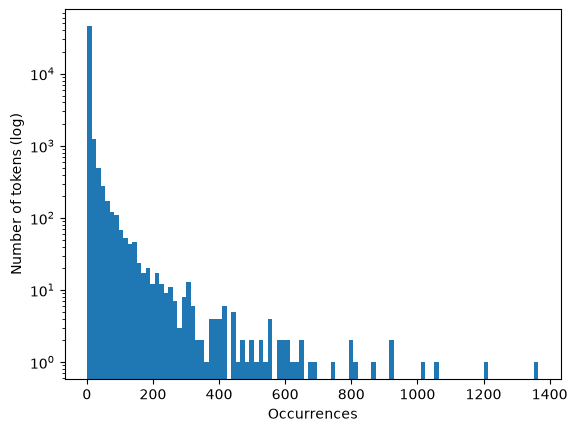

In [7]:
print("Q1")
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

counts = [c for _, c in token_freq]
plt.hist(counts, bins=100, log=True)
plt.xlabel('Occurrences'); plt.ylabel('Number of tokens (log)')
plt.show()


The distribution is extremely right-skewed. Most tokens appear only a few times, while a small number of words ("new", "date", "get", "please") appear over 1,000 times. It has a very long tail.

In [8]:
print("Q2")
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)

lm = LinearRegression().fit(X_train, y_train)
print('Train R^2:', lm.score(X_train, y_train))
print('Test R^2:', lm.score(X_test, y_test))

coefs = pd.Series(lm.coef_, index=X.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

Q2
Train R^2: 0.7659684115003009
Test R^2: 0.6701758721312419


background-image:   -1.201203
localized            0.815112
aging                0.735023
thermal              0.590412
helvetica,           0.587472
intervention        -0.580474
erectile             0.575784
burning             -0.569225
form.                0.560255
april's             -0.525984
dtype: float64

R^2 about 0.77 on the training set and 0.67 on the test set, so there is some overfitting. The largest coefficients are on words like background-image:, localized, aging, thermal, erectile, and intervention. These are mostly spam vocabulary and HTML formatting tokens.

Q3


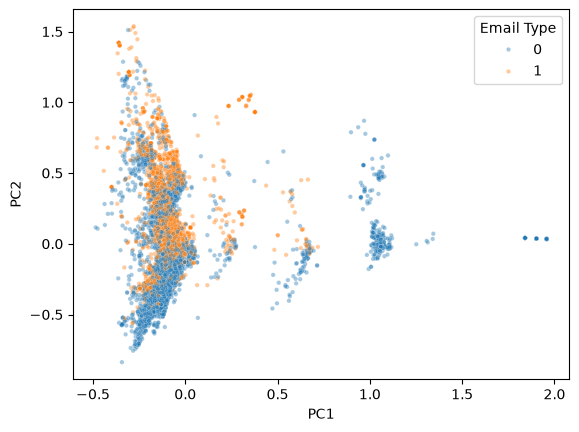

In [9]:
print("Q3")
from sklearn.decomposition import PCA

Z = PCA(n_components=2).fit_transform(X_train)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train, alpha=0.4, s=10)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.show()

The two groups overlap a lot, but they separate somewhat. Legitimate emails stretch out along PC1, and phishing emails stretch out along PC2.


In [10]:
print("Q4")
pca = PCA(n_components=2610).fit(X_train)
Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)

pcr = LinearRegression().fit(Z_train, y_train)
print('Train R^2:', pcr.score(Z_train, y_train))
print('Test R^2:', pcr.score(Z_test, y_test))

Q4
Train R^2: 0.7650509639569709
Test R^2: 0.6718439815209294


R^2 about 0.765 on the training set and 0.672 on the test set. That's essentially the same as the regression on the raw tokens (the test score is very slightly better). Using 2,610 components keeps almost all the information in X.

Q5. 
The word columns are highly correlated, which makes the regular regression unstable. Principal components are uncorrelated, and they're ranked by how much variance they explain. So we can drop the low-variance (mostly noise) components, reducing the number of features and the risk of overfitting without losing much predictive power.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [11]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]